# Pooling Layers

## Overview
Pooling layers reduce the spatial dimensions of feature maps while retaining important information. This notebook covers different types of pooling operations and their effects on CNN architectures.

## Learning Objectives
- Understand different pooling operations (Max, Average, Global)
- Learn how pooling reduces spatial dimensions
- Compare pooling vs strided convolutions
- Implement pooling layers in PyTorch
- Understand when and why to use pooling

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Set style for better plots
plt.style.use('default')
sns.set_palette("husl")

## Types of Pooling Operations

### 1. Max Pooling
- Takes the maximum value in each pooling window
- Preserves the strongest activations
- Most commonly used pooling operation

### 2. Average Pooling
- Takes the average of values in each pooling window
- Smoother downsampling
- Less commonly used than max pooling

### 3. Global Pooling
- Pools over the entire spatial dimension
- Reduces feature maps to single values
- Common in modern architectures

### 4. Adaptive Pooling
- Dynamically resizes input feature maps to a target output size, regardless of the input size.
- Types: Adaptive Max Pooling, Adaptive Avg Pooling
- Works even when input sizes vary. You define the output size, and PyTorch calculates the pooling window and stride automatically.

In [ ]:
# Create a sample feature map for demonstration
def create_sample_feature_map(size=8, seed=42):
    """Create a sample feature map for pooling demonstration"""
    torch.manual_seed(seed)
    # Create a feature map with some structure
    feature_map = torch.randn(1, 1, size, size) * 2 + 1
    # Add some peaks
    feature_map[0, 0, 2:4, 2:4] += 3
    feature_map[0, 0, 5:7, 1:3] += 2
    feature_map[0, 0, 1:3, 5:7] += 2.5
    return feature_map

# Create sample data
sample_fm = create_sample_feature_map()
print(f"Sample feature map shape: {sample_fm.shape}")
print(f"Feature map values:")
print(sample_fm[0, 0].numpy().round(2))

Sample feature map shape: torch.Size([1, 1, 8, 8])
Feature map values:
[[ 4.85  3.97  2.8  -3.21  2.36 -1.47  0.91 -2.21]
 [-0.5   4.3   0.22 -1.81 -0.46  2.38  1.96  2.52]
 [ 4.28  0.68  3.01  4.88 -0.52  5.66  5.1   4.36]
 [ 3.56  3.59  5.22  6.67  0.54  1.08  0.5   2.72]
 [-1.77 -0.74  0.55  4.43  1.64  0.15  1.61 -0.55]
 [-2.12  4.99  1.24 -0.2  -1.55  5.25 -1.47  0.02]
 [-0.83  1.68  3.16  2.05  0.02  3.38 -0.63 -0.47]
 [-1.81  1.07  0.87  2.35  0.8   4.69 -1.37  3.77]]


## Max Pooling Demonstration

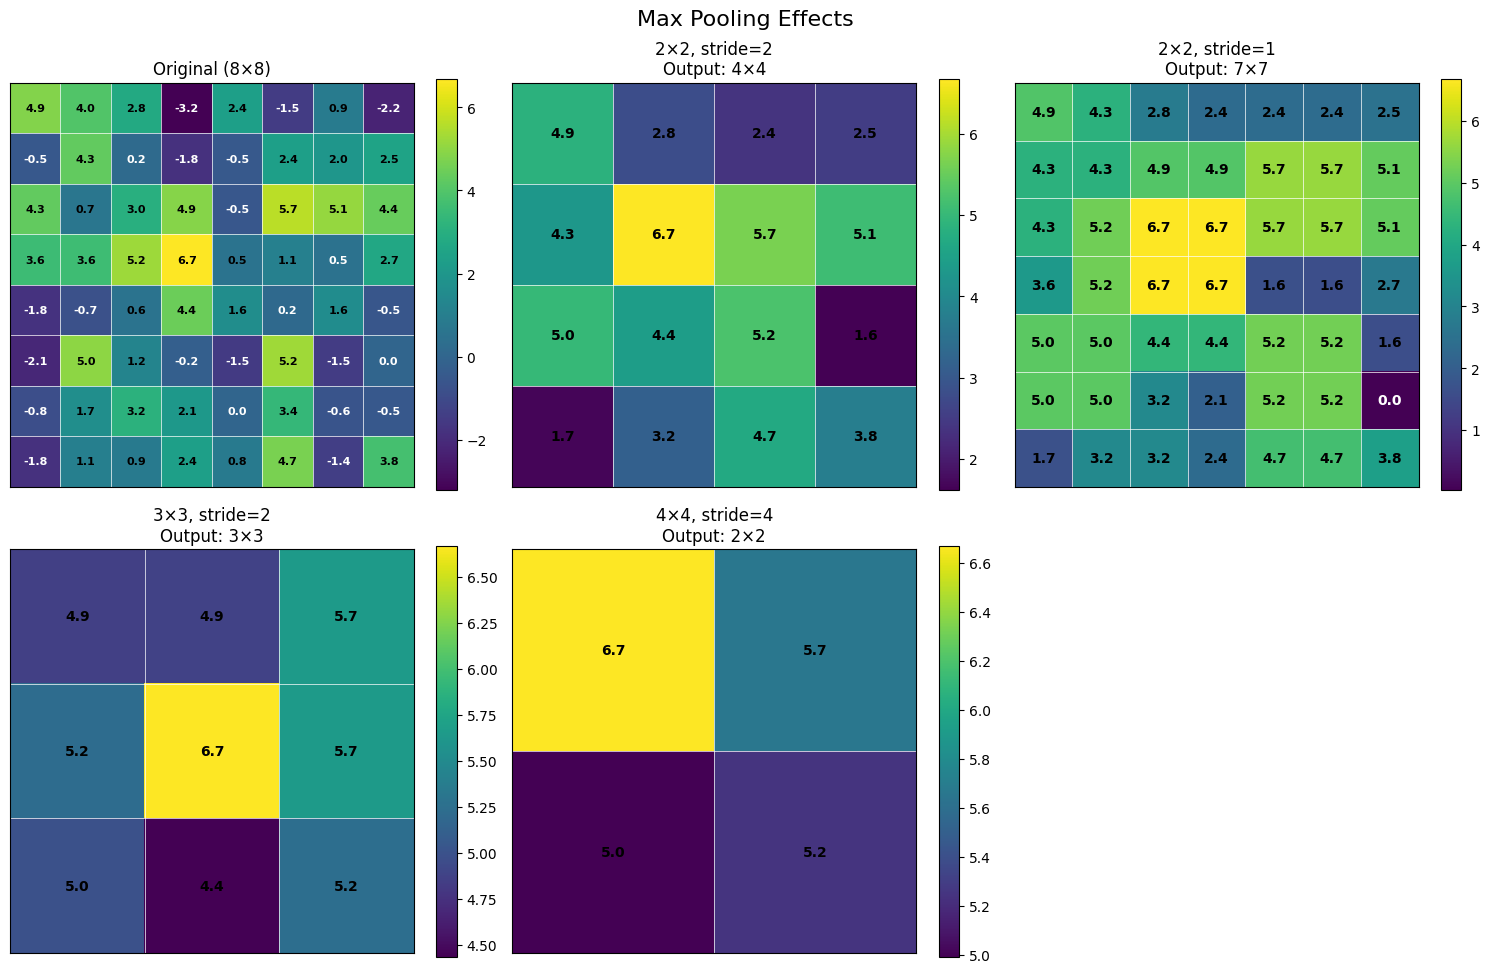


Max Pooling Results:
--------------------------------------------------
2×2, stride=2   | 8×8 → 4×4 | Reduction: 4.0×
2×2, stride=1   | 8×8 → 7×7 | Reduction: 1.3×
3×3, stride=2   | 8×8 → 3×3 | Reduction: 7.1×
4×4, stride=4   | 8×8 → 2×2 | Reduction: 16.0×


In [ ]:
# Demonstrate max pooling with different kernel sizes
def demonstrate_max_pooling(feature_map):
    """Demonstrate max pooling with different configurations"""

    configs = [
        {'kernel_size': 2, 'stride': 2, 'name': '2×2, stride=2'},
        {'kernel_size': 2, 'stride': 1, 'name': '2×2, stride=1'},
        {'kernel_size': 3, 'stride': 2, 'name': '3×3, stride=2'},
        {'kernel_size': 4, 'stride': 4, 'name': '4×4, stride=4'},
    ]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('Max Pooling Effects', fontsize=16)

    # Original feature map
    ax = axes[0, 0]
    original_data = feature_map[0, 0].numpy()
    im = ax.imshow(original_data, cmap='viridis', interpolation='nearest')
    ax.set_title('Original (8×8)')
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)

    # Add numbers to original feature map
    for i in range(original_data.shape[0]):
        for j in range(original_data.shape[1]):
            ax.text(j, i, f'{original_data[i, j]:.1f}',
                   ha='center', va='center',
                   color='white' if original_data[i, j] < 0.5 else 'black',
                   fontsize=8, fontweight='bold')

    # Add grid lines
    for i in range(9):
        ax.axhline(i-0.5, color='white', linewidth=0.5)
        ax.axvline(i-0.5, color='white', linewidth=0.5)

    # Apply different pooling operations
    for idx, config in enumerate(configs[:5]):
        if idx >= 5:  # Only show first 5 configs
            break

        max_pool = nn.MaxPool2d(kernel_size=config['kernel_size'],
                               stride=config['stride'])
        pooled = max_pool(feature_map)
        pooled_data = pooled[0, 0].numpy()

        # Calculate subplot position
        row = (idx + 1) // 3
        col = (idx + 1) % 3

        ax = axes[row, col]
        im = ax.imshow(pooled_data, cmap='viridis', interpolation='nearest')
        ax.set_title(f'{config["name"]}\nOutput: {pooled.shape[2]}×{pooled.shape[3]}')
        ax.set_xticks([])
        ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046)

        # Add numbers to pooled feature map
        for i in range(pooled_data.shape[0]):
            for j in range(pooled_data.shape[1]):
                ax.text(j, i, f'{pooled_data[i, j]:.1f}',
                       ha='center', va='center',
                       color='white' if pooled_data[i, j] < 0.5 else 'black',
                       fontsize=10, fontweight='bold')

        # Add grid lines
        h, w = pooled_data.shape[0], pooled_data.shape[1]
        for i in range(h + 1):
            ax.axhline(i-0.5, color='white', linewidth=0.5)
        for i in range(w + 1):
            ax.axvline(i-0.5, color='white', linewidth=0.5)

    # Hide empty subplot
    axes[1, 2].set_visible(False)

    plt.tight_layout()
    plt.show()

    # Print numerical results
    print("\nMax Pooling Results:")
    print("-" * 50)
    for config in configs:
        max_pool = nn.MaxPool2d(kernel_size=config['kernel_size'],
                               stride=config['stride'])
        pooled = max_pool(feature_map)
        reduction = (feature_map.shape[2] * feature_map.shape[3]) / (pooled.shape[2] * pooled.shape[3])
        print(f"{config['name']:15} | {feature_map.shape[2]}×{feature_map.shape[3]} → {pooled.shape[2]}×{pooled.shape[3]} | Reduction: {reduction:.1f}×")

demonstrate_max_pooling(sample_fm)

## Average Pooling vs Max Pooling

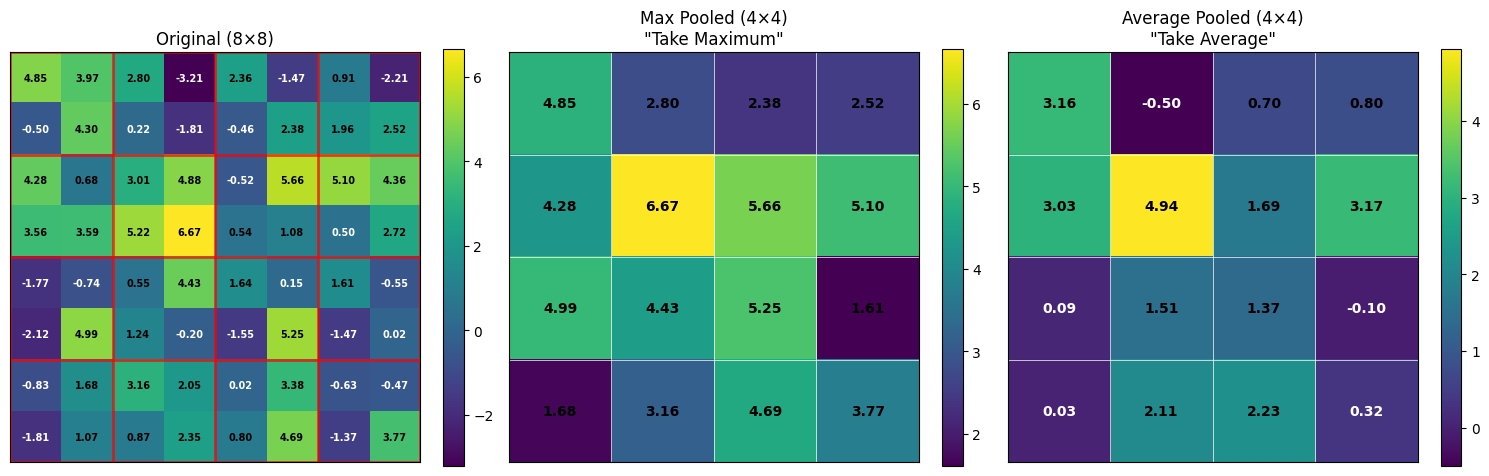

🔍 DETAILED CALCULATION EXAMPLE:
Looking at top-left 2×2 region from original:
Region values: [[4.85, 3.97],
                [-0.50, 4.30]]

Max Pooling: max(4.85, 3.97, -0.50, 4.30) = 4.85
Avg Pooling: (4.85 + 3.97 + -0.50 + 4.30) ÷ 4 = 3.16

Result in output[0,0]: Max=4.85, Avg=3.16

📊 STATISTICAL COMPARISON:
---------------------------------------------
Original max value: 6.669
Original mean value: 1.534
Original std: 2.408

Max pooled max value: 6.669
Max pooled mean value: 3.991
Max pooled std: 1.487

Avg pooled max value: 4.944
Avg pooled mean value: 1.534
Avg pooled std: 1.502

💡 KEY DIFFERENCES:
✅ Max pooling preserves strong activations (keeps highest values)
✅ Average pooling provides smoother downsampling (blends values)
✅ Max pooling typically retains more discriminative features
✅ Average pooling reduces noise but may lose important details

🎯 VALUE PRESERVATION:
Max pooling preserves 100.0% of strongest activation
Avg pooling preserves 74.1% of strongest activation


In [ ]:
# Compare max pooling vs average pooling
def compare_pooling_types(feature_map):
    """Compare different pooling operations"""

    kernel_size = 2
    stride = 2

    # Apply different pooling operations
    max_pool = nn.MaxPool2d(kernel_size=kernel_size, stride=stride)
    avg_pool = nn.AvgPool2d(kernel_size=kernel_size, stride=stride)

    max_pooled = max_pool(feature_map)
    avg_pooled = avg_pool(feature_map)

    # Get numpy arrays for easier handling
    original_data = feature_map[0, 0].numpy()
    max_data = max_pooled[0, 0].numpy()
    avg_data = avg_pooled[0, 0].numpy()

    # Visualize comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original
    im1 = axes[0].imshow(original_data, cmap='viridis', interpolation='nearest')
    axes[0].set_title('Original (8×8)')
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    plt.colorbar(im1, ax=axes[0], fraction=0.046)

    # Add numbers to original
    for i in range(original_data.shape[0]):
        for j in range(original_data.shape[1]):
            axes[0].text(j, i, f'{original_data[i, j]:.2f}',
                        ha='center', va='center',
                        color='white' if original_data[i, j] < 0.5 else 'black',
                        fontsize=7, fontweight='bold')

    # Add grid lines to show pooling regions
    for i in range(0, 9, 2):
        axes[0].axhline(i-0.5, color='red', linewidth=2, alpha=0.7)
        axes[0].axvline(i-0.5, color='red', linewidth=2, alpha=0.7)

    # Max pooled
    im2 = axes[1].imshow(max_data, cmap='viridis', interpolation='nearest')
    axes[1].set_title('Max Pooled (4×4)\n"Take Maximum"')
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    plt.colorbar(im2, ax=axes[1], fraction=0.046)

    # Add numbers to max pooled
    for i in range(max_data.shape[0]):
        for j in range(max_data.shape[1]):
            axes[1].text(j, i, f'{max_data[i, j]:.2f}',
                        ha='center', va='center',
                        color='white' if max_data[i, j] < 0.5 else 'black',
                        fontsize=10, fontweight='bold')

    # Add grid lines
    for i in range(5):
        axes[1].axhline(i-0.5, color='white', linewidth=0.5)
        axes[1].axvline(i-0.5, color='white', linewidth=0.5)

    # Average pooled
    im3 = axes[2].imshow(avg_data, cmap='viridis', interpolation='nearest')
    axes[2].set_title('Average Pooled (4×4)\n"Take Average"')
    axes[2].set_xticks([])
    axes[2].set_yticks([])
    plt.colorbar(im3, ax=axes[2], fraction=0.046)

    # Add numbers to average pooled
    for i in range(avg_data.shape[0]):
        for j in range(avg_data.shape[1]):
            axes[2].text(j, i, f'{avg_data[i, j]:.2f}',
                        ha='center', va='center',
                        color='white' if avg_data[i, j] < 0.5 else 'black',
                        fontsize=10, fontweight='bold')

    # Add grid lines
    for i in range(5):
        axes[2].axhline(i-0.5, color='white', linewidth=0.5)
        axes[2].axvline(i-0.5, color='white', linewidth=0.5)

    plt.tight_layout()
    plt.show()

    # Show detailed calculation example
    print("🔍 DETAILED CALCULATION EXAMPLE:")
    print("=" * 50)
    print("Looking at top-left 2×2 region from original:")

    # Extract top-left 2x2 region
    region = original_data[0:2, 0:2]
    max_val = np.max(region)
    avg_val = np.mean(region)

    print(f"Region values: [[{region[0,0]:.2f}, {region[0,1]:.2f}],")
    print(f"                [{region[1,0]:.2f}, {region[1,1]:.2f}]]")
    print()
    print(f"Max Pooling: max({region[0,0]:.2f}, {region[0,1]:.2f}, {region[1,0]:.2f}, {region[1,1]:.2f}) = {max_val:.2f}")
    print(f"Avg Pooling: ({region[0,0]:.2f} + {region[0,1]:.2f} + {region[1,0]:.2f} + {region[1,1]:.2f}) ÷ 4 = {avg_val:.2f}")
    print()
    print(f"Result in output[0,0]: Max={max_data[0,0]:.2f}, Avg={avg_data[0,0]:.2f}")

    # Numerical comparison
    print("\n📊 STATISTICAL COMPARISON:")
    print("-" * 45)
    print(f"Original max value: {feature_map.max().item():.3f}")
    print(f"Original mean value: {feature_map.mean().item():.3f}")
    print(f"Original std: {feature_map.std().item():.3f}")
    print()
    print(f"Max pooled max value: {max_pooled.max().item():.3f}")
    print(f"Max pooled mean value: {max_pooled.mean().item():.3f}")
    print(f"Max pooled std: {max_pooled.std().item():.3f}")
    print()
    print(f"Avg pooled max value: {avg_pooled.max().item():.3f}")
    print(f"Avg pooled mean value: {avg_pooled.mean().item():.3f}")
    print(f"Avg pooled std: {avg_pooled.std().item():.3f}")

    print("\n💡 KEY DIFFERENCES:")
    print("✅ Max pooling preserves strong activations (keeps highest values)")
    print("✅ Average pooling provides smoother downsampling (blends values)")
    print("✅ Max pooling typically retains more discriminative features")
    print("✅ Average pooling reduces noise but may lose important details")

    # Value preservation analysis
    max_preserved = (max_pooled.max().item() / feature_map.max().item()) * 100
    avg_preserved = (avg_pooled.max().item() / feature_map.max().item()) * 100

    print(f"\n🎯 VALUE PRESERVATION:")
    print(f"Max pooling preserves {max_preserved:.1f}% of strongest activation")
    print(f"Avg pooling preserves {avg_preserved:.1f}% of strongest activation")

compare_pooling_types(sample_fm)

## Global Pooling Operations

📊 Input feature maps shape: torch.Size([1, 4, 6, 6])
Total elements: 144

🌍 Global Pooling Results:
------------------------------
Global Average Pooling: torch.Size([1, 4, 6, 6]) → torch.Size([1, 4, 1, 1])
Global Max Pooling: torch.Size([1, 4, 6, 6]) → torch.Size([1, 4, 1, 1])
Reduction factor: 36×

After flattening for classification:
GAP: torch.Size([1, 4]) (ready for classifier)
GMP: torch.Size([1, 4]) (ready for classifier)



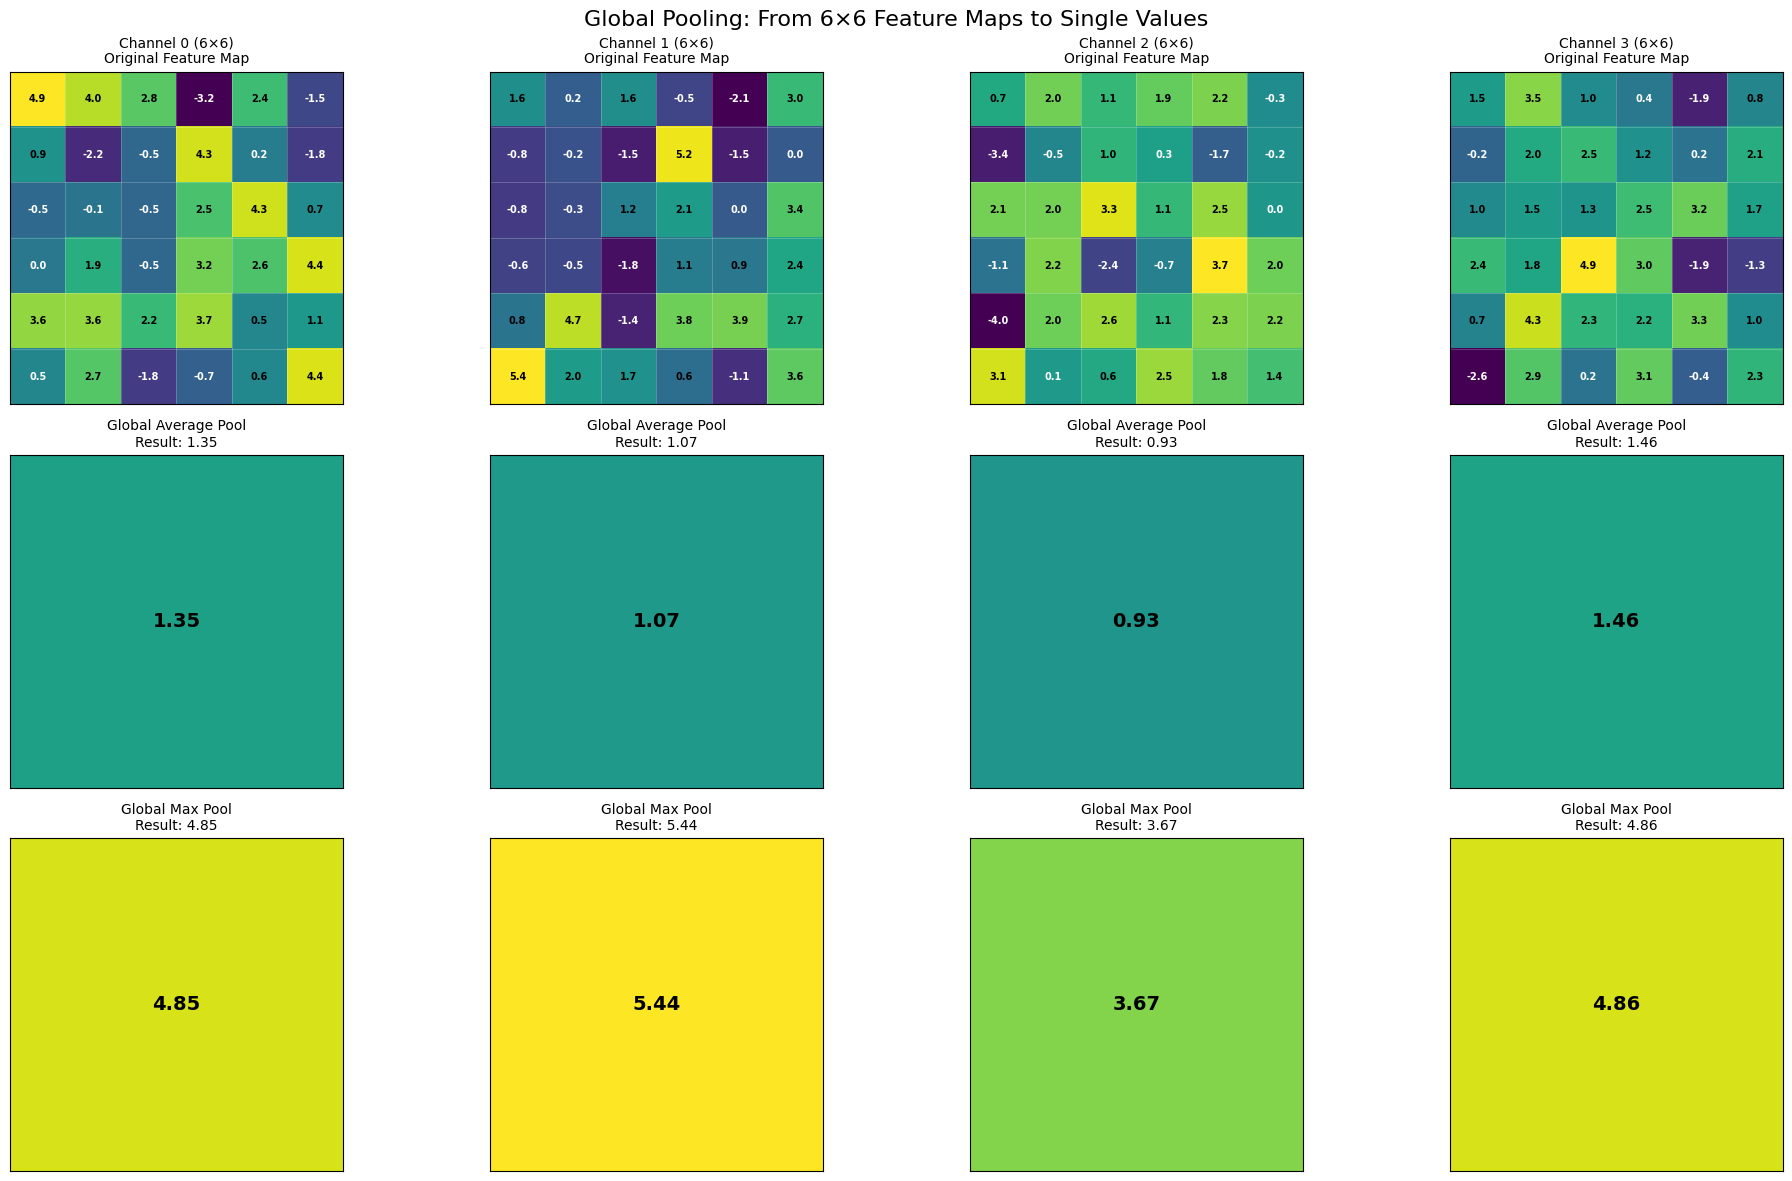

🔍 DETAILED CALCULATION EXAMPLE (Channel 0):
Original 6×6 feature map:
[  4.9   4.0   2.8  -3.2   2.4  -1.5]
[  0.9  -2.2  -0.5   4.3   0.2  -1.8]
[ -0.5  -0.1  -0.5   2.5   4.3   0.7]
[  0.0   1.9  -0.5   3.2   2.6   4.4]
[  3.6   3.6   2.2   3.7   0.5   1.1]
[  0.5   2.7  -1.8  -0.7   0.6   4.4]

📊 Global Average Pooling Calculation:
All 36 values: 4.9, 4.0, 2.8, -3.2, 2.4, -1.5, 0.9, -2.2, -0.5, 4.3... (showing first 10)
Sum of all values: 48.43
Average: 48.43 ÷ 36 = 1.345
GAP Result: 1.345 ✅

🎯 Global Max Pooling Calculation:
Maximum value in 6×6 map: 4.854
GMP Result: 4.854 ✅

⚖️ COMPARISON FOR CHANNEL 0:
------------------------------
GAP captures overall activation level: 1.345
GMP captures strongest activation: 4.854
Difference: 3.508

📤 CLASSIFICATION-READY VECTORS:
-----------------------------------
GAP vector: [1.35, 1.07, 0.93, 1.46]
GMP vector: [4.85, 5.44, 3.67, 4.86]

💡 These 4 numbers summarize the entire 6×6×4 feature volume!

🎯 KEY INSIGHTS:
✅ Global pooling eliminate

In [ ]:
# Demonstrate global pooling
def demonstrate_global_pooling():
    """Demonstrate global pooling operations"""

    # Create a smaller, more manageable feature map for visualization
    batch_size, channels, height, width = 1, 4, 6, 6
    torch.manual_seed(42)  # For reproducible results
    feature_maps = torch.randn(batch_size, channels, height, width) * 2 + 1

    print(f"📊 Input feature maps shape: {feature_maps.shape}")
    print(f"Total elements: {feature_maps.numel():,}")
    print()

    # Global Average Pooling
    global_avg_pool = nn.AdaptiveAvgPool2d(1)
    gap_output = global_avg_pool(feature_maps)

    # Global Max Pooling
    global_max_pool = nn.AdaptiveMaxPool2d(1)
    gmp_output = global_max_pool(feature_maps)

    print("🌍 Global Pooling Results:")
    print("-" * 30)
    print(f"Global Average Pooling: {feature_maps.shape} → {gap_output.shape}")
    print(f"Global Max Pooling: {feature_maps.shape} → {gmp_output.shape}")
    print(f"Reduction factor: {feature_maps.numel() / gap_output.numel():.0f}×")
    print()

    # Flatten for classification
    gap_flattened = gap_output.view(gap_output.size(0), -1)
    gmp_flattened = gmp_output.view(gmp_output.size(0), -1)

    print(f"After flattening for classification:")
    print(f"GAP: {gap_flattened.shape} (ready for classifier)")
    print(f"GMP: {gmp_flattened.shape} (ready for classifier)")
    print()

    # Get numpy arrays for easier handling
    feature_data = feature_maps[0].numpy()  # Shape: (4, 6, 6)
    gap_data = gap_output[0].numpy()       # Shape: (4, 1, 1)
    gmp_data = gmp_output[0].numpy()       # Shape: (4, 1, 1)

    # Visualize feature maps with detailed calculations
    fig, axes = plt.subplots(3, 4, figsize=(20, 12))
    fig.suptitle('Global Pooling: From 6×6 Feature Maps to Single Values', fontsize=16)

    # Show all 4 channels
    for i in range(4):
        channel_data = feature_data[i]
        gap_value = gap_data[i, 0, 0]
        gmp_value = gmp_data[i, 0, 0]

        # Row 1: Original feature maps with numbers
        axes[0, i].imshow(channel_data, cmap='viridis', interpolation='nearest')
        axes[0, i].set_title(f'Channel {i} (6×6)\nOriginal Feature Map', fontsize=10)
        axes[0, i].set_xticks([])
        axes[0, i].set_yticks([])

        # Add numbers to each cell
        for row in range(6):
            for col in range(6):
                value = channel_data[row, col]
                color = 'white' if value < 0.5 else 'black'
                axes[0, i].text(col, row, f'{value:.1f}',
                               ha='center', va='center',
                               color=color, fontsize=7, fontweight='bold')

        # Add grid lines
        for j in range(7):
            axes[0, i].axhline(j-0.5, color='white', linewidth=0.5, alpha=0.3)
            axes[0, i].axvline(j-0.5, color='white', linewidth=0.5, alpha=0.3)

        # Row 2: Global Average Pooling result
        gap_pixel = np.array([[gap_value]])
        axes[1, i].imshow(gap_pixel, cmap='viridis', interpolation='nearest',
                         vmin=feature_data.min(), vmax=feature_data.max())
        axes[1, i].set_title(f'Global Average Pool\nResult: {gap_value:.2f}', fontsize=10)
        axes[1, i].set_xticks([])
        axes[1, i].set_yticks([])
        axes[1, i].text(0, 0, f'{gap_value:.2f}',
                       ha='center', va='center',
                       color='white' if gap_value < 0.5 else 'black',
                       fontsize=14, fontweight='bold')

        # Row 3: Global Max Pooling result
        gmp_pixel = np.array([[gmp_value]])
        axes[2, i].imshow(gmp_pixel, cmap='viridis', interpolation='nearest',
                         vmin=feature_data.min(), vmax=feature_data.max())
        axes[2, i].set_title(f'Global Max Pool\nResult: {gmp_value:.2f}', fontsize=10)
        axes[2, i].set_xticks([])
        axes[2, i].set_yticks([])
        axes[2, i].text(0, 0, f'{gmp_value:.2f}',
                       ha='center', va='center',
                       color='white' if gmp_value < 0.5 else 'black',
                       fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Show detailed calculations for one channel
    print("🔍 DETAILED CALCULATION EXAMPLE (Channel 0):")
    print("=" * 55)
    channel_0 = feature_data[0]
    print("Original 6×6 feature map:")
    for row in range(6):
        row_str = " ".join([f"{channel_0[row, col]:5.1f}" for col in range(6)])
        print(f"[{row_str}]")

    print(f"\n📊 Global Average Pooling Calculation:")
    all_values = channel_0.flatten()
    print(f"All 36 values: {', '.join([f'{v:.1f}' for v in all_values[:10]])}... (showing first 10)")
    print(f"Sum of all values: {np.sum(all_values):.2f}")
    print(f"Average: {np.sum(all_values):.2f} ÷ 36 = {np.mean(all_values):.3f}")
    print(f"GAP Result: {gap_data[0, 0, 0]:.3f} ✅")

    print(f"\n🎯 Global Max Pooling Calculation:")
    print(f"Maximum value in 6×6 map: {np.max(all_values):.3f}")
    print(f"GMP Result: {gmp_data[0, 0, 0]:.3f} ✅")

    # Compare the approaches
    print(f"\n⚖️ COMPARISON FOR CHANNEL 0:")
    print("-" * 30)
    print(f"GAP captures overall activation level: {gap_data[0, 0, 0]:.3f}")
    print(f"GMP captures strongest activation: {gmp_data[0, 0, 0]:.3f}")
    print(f"Difference: {abs(gap_data[0, 0, 0] - gmp_data[0, 0, 0]):.3f}")

    # Show the final classification-ready vectors
    print(f"\n📤 CLASSIFICATION-READY VECTORS:")
    print("-" * 35)
    print(f"GAP vector: [{', '.join([f'{gap_data[i, 0, 0]:.2f}' for i in range(4)])}]")
    print(f"GMP vector: [{', '.join([f'{gmp_data[i, 0, 0]:.2f}' for i in range(4)])}]")
    print(f"\n💡 These 4 numbers summarize the entire {height}×{width}×{channels} feature volume!")

    print(f"\n🎯 KEY INSIGHTS:")
    print("✅ Global pooling eliminates spatial dimensions completely")
    print("✅ GAP provides smooth, averaged representation")
    print("✅ GMP preserves only the strongest activations")
    print("✅ Output is ready for final classification layer")
    print("✅ Dramatic size reduction: 144 → 4 values (36× smaller!)")

    return gap_output, gmp_output

gap_out, gmp_out = demonstrate_global_pooling()

## Adaptive Pooling

🔄 ADAPTIVE POOLING: The Smart Size-Flexible Solution
🎯 Goal: Same output size regardless of input size!

In [ ]:
# Create simple, visualizable inputs of different sizes
torch.manual_seed(42)
inputs = [
    torch.randn(1, 1, 4, 4) * 2 + 1,   # Small: 4×4
    torch.randn(1, 1, 6, 6) * 2 + 1,   # Medium: 6×6
    torch.randn(1, 1, 8, 8) * 2 + 1,   # Large: 8×8
    torch.randn(1, 1, 6, 4) * 2 + 1,   # Irregular: 6×4
]

input_names = ["Small (4×4)", "Medium (6×6)", "Large (8×8)", "Irregular (6×4)"]

# Adaptive pooling layers
adaptive_avg_2x2 = nn.AdaptiveAvgPool2d((2, 2))  # Always → 2×2
adaptive_avg_1x1 = nn.AdaptiveAvgPool2d(1)       # Always → 1×1

for i, (input_tensor, name) in enumerate(zip(inputs, input_names)):
  out_2x2 = adaptive_avg_2x2(input_tensor)
  out_1x1 = adaptive_avg_1x1(input_tensor)
  print(f"{name:15} | {list(input_tensor.shape[2:])} → 2×2: {list(out_2x2.shape[2:])} | 1×1: {list(out_1x1.shape[2:])}")

Small (4×4)     | [4, 4] → 2×2: [2, 2] | 1×1: [1, 1]
Medium (6×6)    | [6, 6] → 2×2: [2, 2] | 1×1: [1, 1]
Large (8×8)     | [8, 8] → 2×2: [2, 2] | 1×1: [1, 1]
Irregular (6×4) | [6, 4] → 2×2: [2, 2] | 1×1: [1, 1]


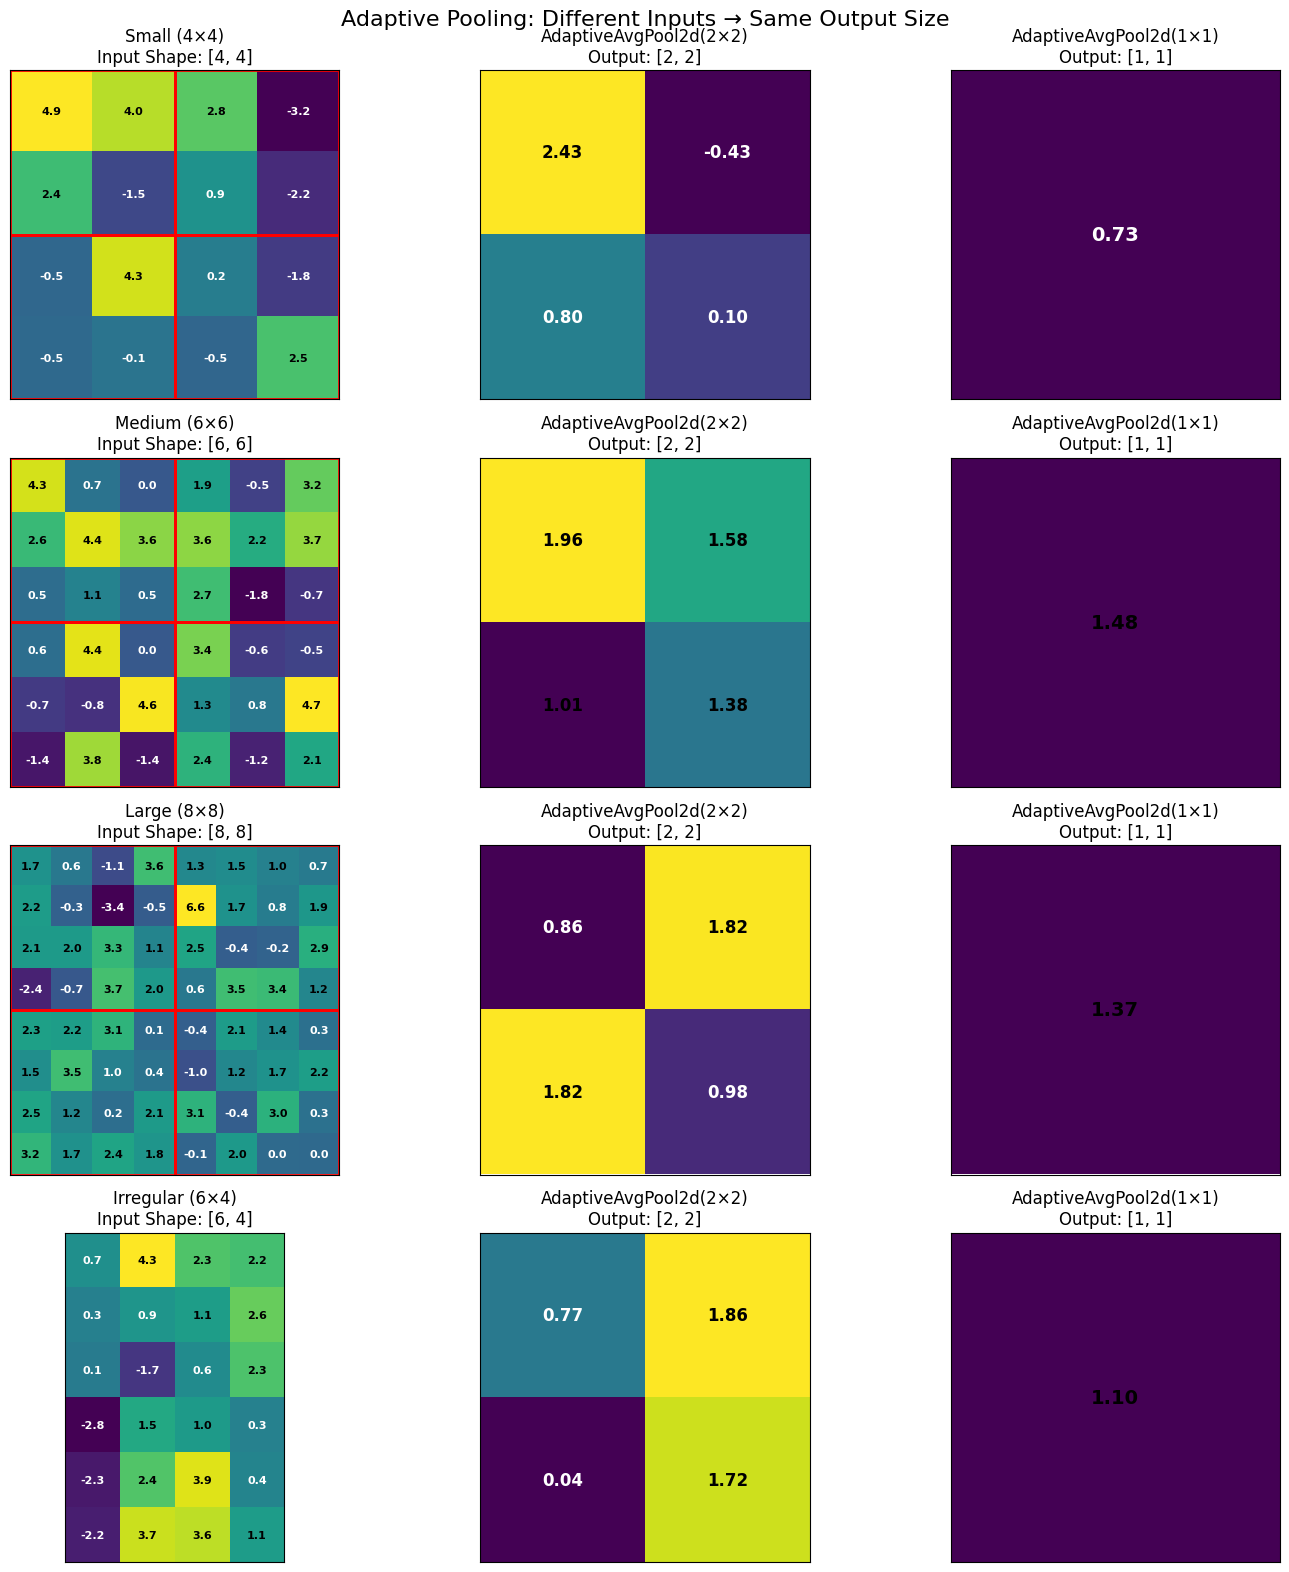

In [ ]:
# Visualize adaptive pooling in action
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
fig.suptitle('Adaptive Pooling: Different Inputs → Same Output Size', fontsize=16)

for i, (input_tensor, name) in enumerate(zip(inputs, input_names)):
    # Get data for visualization
    input_data = input_tensor[0, 0].numpy()

    # Apply adaptive pooling
    out_2x2 = adaptive_avg_2x2(input_tensor)
    out_1x1 = adaptive_avg_1x1(input_tensor)

    out_2x2_data = out_2x2[0, 0].numpy()
    out_1x1_data = out_1x1[0, 0].numpy()

    # Visualize input
    axes[i, 0].imshow(input_data, cmap='viridis', interpolation='nearest')
    axes[i, 0].set_title(f'{name}\nInput Shape: {list(input_tensor.shape[2:])}')
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])

    # Add numbers to input
    for row in range(input_data.shape[0]):
        for col in range(input_data.shape[1]):
            value = input_data[row, col]
            color = 'white' if value < 1.0 else 'black'
            axes[i, 0].text(col, row, f'{value:.1f}',
                            ha='center', va='center',
                            color=color, fontsize=8, fontweight='bold')

    # Add adaptive pooling region indicators
    h, w = input_data.shape
    if h == w:  # Square inputs
        region_size = h // 2
        for r in range(0, h, region_size):
            for c in range(0, w, region_size):
                axes[i, 0].add_patch(plt.Rectangle((c-0.5, r-0.5), region_size, region_size,
                                                  fill=False, edgecolor='red', linewidth=2))

    # Visualize 2×2 output
    axes[i, 1].imshow(out_2x2_data, cmap='viridis', interpolation='nearest')
    axes[i, 1].set_title(f'AdaptiveAvgPool2d(2×2)\nOutput: {list(out_2x2.shape[2:])}')
    axes[i, 1].set_xticks([])
    axes[i, 1].set_yticks([])

    # Add numbers to 2×2 output
    for row in range(2):
        for col in range(2):
            value = out_2x2_data[row, col]
            color = 'white' if value < 1.0 else 'black'
            axes[i, 1].text(col, row, f'{value:.2f}',
                            ha='center', va='center',
                            color=color, fontsize=12, fontweight='bold')

    # Visualize 1×1 output
    axes[i, 2].imshow(out_1x1_data.reshape(1,1), cmap='viridis', interpolation='nearest')
    axes[i, 2].set_title(f'AdaptiveAvgPool2d(1×1)\nOutput: {list(out_1x1.shape[2:])}')
    axes[i, 2].set_xticks([])
    axes[i, 2].set_yticks([])
    axes[i, 2].text(0, 0, f'{out_1x1_data[0,0]:.2f}',
                    ha='center', va='center',
                    color='white' if out_1x1_data[0,0] < 1.0 else 'black',
                    fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

🔍 DETAILED CALCULATION EXAMPLE:

Let's see how 6×6 input becomes 2×2 output:

In [ ]:
example_input = inputs[1][0, 0].numpy()  # 6×6 input
example_output = adaptive_avg_2x2(inputs[1])[0, 0].numpy()  # 2×2 output

print("\n📐 6×6 Input divided into 2×2 regions:")
print("Each region is 3×3 pixels")
print()

# Show the 4 regions and their calculations
regions = [
    ("Top-Left", example_input[0:3, 0:3]),
    ("Top-Right", example_input[0:3, 3:6]),
    ("Bottom-Left", example_input[3:6, 0:3]),
    ("Bottom-Right", example_input[3:6, 3:6])
]

for idx, (region_name, region_data) in enumerate(regions):
    avg_value = np.mean(region_data)
    output_row, output_col = idx // 2, idx % 2

    print(f"{region_name} (3×3) region:")
    for row in range(3):
        row_str = " ".join([f"{region_data[row, col]:4.1f}" for col in range(3)])
        print(f"  [{row_str}]")
    print(f"  Average: {avg_value:.3f}")
    print(f"  → Output[{output_row},{output_col}] = {example_output[output_row, output_col]:.3f} ✅")
    print()


📐 6×6 Input divided into 2×2 regions:
Each region is 3×3 pixels

Top-Left (3×3) region:
  [ 4.3  0.7  0.0]
  [ 2.6  4.4  3.6]
  [ 0.5  1.1  0.5]
  Average: 1.957
  → Output[0,0] = 1.957 ✅

Top-Right (3×3) region:
  [ 1.9 -0.5  3.2]
  [ 3.6  2.2  3.7]
  [ 2.7 -1.8 -0.7]
  Average: 1.579
  → Output[0,1] = 1.579 ✅

Bottom-Left (3×3) region:
  [ 0.6  4.4  0.0]
  [-0.7 -0.8  4.6]
  [-1.4  3.8 -1.4]
  Average: 1.012
  → Output[1,0] = 1.012 ✅

Bottom-Right (3×3) region:
  [ 3.4 -0.6 -0.5]
  [ 1.3  0.8  4.7]
  [ 2.4 -1.2  2.1]
  Average: 1.381
  → Output[1,1] = 1.381 ✅



🏗️ PRACTICAL EXAMPLE: Flexible CNN Architecture

In [ ]:
class FlexibleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(FlexibleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
        )

        # 🎯 KEY: Adaptive pooling makes output size predictable!
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))  # Always 4×4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),  # Always 64×4×4 = 1024 inputs
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)  # 🔄 Magic happens here!
        x = self.classifier(x)
        return x

# Test with different input sizes
flexible_model = FlexibleCNN()

test_inputs = [
    torch.randn(1, 3, 32, 32),   # CIFAR-10 size
    torch.randn(1, 3, 64, 64),   # Medium size
    torch.randn(1, 3, 224, 224), # ImageNet size
    torch.randn(1, 3, 128, 96),  # Irregular size
]

test_names = ["CIFAR-10 (32×32)", "Medium (64×64)", "ImageNet (224×224)", "Irregular (128×96)"]

print("Testing same model on different input sizes:")
print("-" * 45)

for i, (test_input, name) in enumerate(zip(test_inputs, test_names)):
    with torch.no_grad():
        output = flexible_model(test_input)
        print(f"{name:20} | Input: {list(test_input.shape[2:])} → Output: {list(output.shape)} ✅")

Testing same model on different input sizes:
---------------------------------------------
CIFAR-10 (32×32)     | Input: [32, 32] → Output: [1, 10] ✅
Medium (64×64)       | Input: [64, 64] → Output: [1, 10] ✅
ImageNet (224×224)   | Input: [224, 224] → Output: [1, 10] ✅
Irregular (128×96)   | Input: [128, 96] → Output: [1, 10] ✅


💡 MAGIC: Same model works on ALL input sizes!
  - Adaptive pooling always produces 4×4 feature maps
  - Classifier always gets 1024 features (64×4×4)
  - No architecture changes needed!
    
🎯 KEY BENEFITS:"
 - ✅ One model handles multiple input sizes
 - ✅ Perfect for transfer learning
 - ✅ Simplifies architecture design
 - ✅ Used in modern networks (ResNet, EfficientNet)
 - ✅ Enables flexible deployment
    

## Key Takeaways

### Types of Pooling:
- **Max Pooling**: Preserves strongest activations, most common
- **Average Pooling**: Smoother downsampling, less information loss
- **Global Pooling**: Reduces to single value per channel
- **Adaptive Pooling**: Handles variable input sizes

### Benefits of Pooling:
- **Dimensionality reduction**: Reduces spatial size
- **Translation invariance**: Small shifts don't affect output much
- **Computational efficiency**: Fewer parameters in subsequent layers
- **Overfitting reduction**: Acts as regularization
